# 02 · EEGNet-8,2 (Lawhern i in. 2018)

In [1]:
from pathlib import Path
import json
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (
    roc_auc_score, average_precision_score, accuracy_score, balanced_accuracy_score,
    f1_score, precision_score, recall_score, confusion_matrix,
    ConfusionMatrixDisplay, RocCurveDisplay,
)
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.constraints import max_norm

print('TensorFlow:', tf.__version__)

2026-11-15 20:45:15.746192: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1794771915.853894  260433 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1794771915.883589  260433 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2026-11-15 20:45:16.125932: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


TensorFlow: 2.18.0


In [ ]:
TRYB_TESTOWY = False
USE_ICA = True
USE_ALL_64_CHANNELS = True
TAG = (
    ('ica' if USE_ICA else 'bez_ica')
    + ('_64ch' if USE_ALL_64_CHANNELS else '_19ch'))

ROOT = Path.cwd()
DATA_DIR = ROOT / f'benchmark_data_{TAG}'
RESULTS_DIR = ROOT / f'results_{TAG}' / 'eegnet'

FOLDS_TO_RUN = [1] if TRYB_TESTOWY else [1,2,3,4,5]
MAX_EPOCHS = 20 if TRYB_TESTOWY else 200
BATCH_SIZE = 32
SEED = 42
THRESHOLD = 0.5 

print('Dane:', DATA_DIR)
print('Wyniki:', RESULTS_DIR)
print('Foldy:', FOLDS_TO_RUN, 'maks. epok:', MAX_EPOCHS)

Dane: /home/eliza/mgr-phd/benchmark_data_ica_64ch
Wyniki: /home/eliza/mgr-phd/results_ica_64ch/eegnet
Foldy: [1, 2, 3, 4, 5] maks. epok: 200


## 2. Wczytaj wspólne `X`, `y`, identyfikatory i podziały

In [ ]:
if not (DATA_DIR / 'epochs.npz').is_file() or not (DATA_DIR / 'splits.npz').is_file():
    raise FileNotFoundError('Brak przygotowanych danych. Uruchom najpierw notebook 01.')
with np.load(DATA_DIR / 'epochs.npz', allow_pickle=False) as dataset:
    X = dataset['X'].astype(np.float32)
    y = dataset['y'].astype(np.uint8)
    subjects = dataset['subjects']
    trial_ids = dataset['trial_ids']
    channel_names = dataset['channel_names'].tolist()
with np.load(DATA_DIR / 'splits.npz', allow_pickle=False) as saved:
    splits = {key: saved[key] for key in saved.files}
manifest = json.loads((DATA_DIR / 'manifest.json').read_text(encoding='utf-8'))
assert manifest['demo_mode'] == TRYB_TESTOWY, 'Niezgodny TRYB_TESTOWY z przygotowanym zbiorem.'
assert X.shape[1] == 64
assert manifest['channel_mode'] == '64'
assert manifest['ica'] is True

assert X.shape[2] == 481
assert len(X) == len(y) == len(subjects) == len(trial_ids)
print('Wejście X:', X.shape, 'jednostka:', manifest['units'])
print('Uczestnicy:', len(np.unique(subjects)))
print('Etykiety:', dict(zip(*np.unique(y, return_counts=True))))
if manifest['demo_mode']:
    print('UWAGA: dane demonstracyjne; nie raportuj metryk jako wyników porównania naukowego.')

Wejście X: (19689, 64, 481) jednostka: microvolts
Uczestnicy: 109
Etykiety: {0: 14739, 1: 4950}


## 3. Kontrola podziału i skalowanie wejścia

In [4]:
def normalize_for_eegnet(train, val, test):
    mean = train.mean(axis=(0, 2), keepdims=True)
    std = train.std(axis=(0, 2), keepdims=True)
    std = np.where(std < 1e-6, 1.0, std)
    def convert(a):
        return ((a - mean) / std).astype(np.float32)[..., None]
    return convert(train), convert(val), convert(test), mean, std

first_fold = FOLDS_TO_RUN[0]
tr, va, te = (splits[f'{name}_{first_fold}'] for name in ('train','val','test'))
sets = [set(subjects[idx]) for idx in (tr,va,te)]
assert not (sets[0] & sets[1] or sets[0] & sets[2] or sets[1] & sets[2])
Xtr, Xva, Xte, mu, sigma = normalize_for_eegnet(X[tr], X[va], X[te])
print('Train:', Xtr.shape, 'Val:', Xva.shape, 'Test:', Xte.shape)
print('Liczba osób:', *(len(s) for s in sets))
print('Odchylenia train z pierwszych 5 kanałów:', np.round(sigma[0, :5, 0], 3))

Train: (12482, 64, 481, 1) Val: (3235, 64, 481, 1) Test: (3972, 64, 481, 1)
Liczba osób: 69 18 22
Odchylenia train z pierwszych 5 kanałów: [16.254 15.576 15.299 15.197 14.869]


## 4. Architektura EEGNet-8,2

In [5]:
def build_eegnet(chans, samples, dropout=0.5):
    inputs = keras.Input(shape=(chans, samples, 1), name='EEG')
    x = layers.Conv2D(8, (1,64), padding='same', use_bias=False, name='temporal_conv')(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.DepthwiseConv2D(
        (chans,1), depth_multiplier=2, use_bias=False,
        depthwise_constraint=max_norm(1.0), name='spatial_depthwise'
    )(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('elu')(x)
    x = layers.AveragePooling2D((1,4))(x)
    x = layers.Dropout(dropout)(x)
    x = layers.SeparableConv2D(16, (1,16), padding='same', use_bias=False, name='separable_conv')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('elu')(x)
    x = layers.AveragePooling2D((1,8))(x)
    x = layers.Dropout(dropout)(x)
    x = layers.Flatten()(x)
    x = layers.Dense(2, kernel_constraint=max_norm(0.25), name='classifier')(x)
    outputs = layers.Activation('softmax', name='probabilities')(x)
    model = keras.Model(inputs, outputs, name='EEGNet_8_2')
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-3),
        loss='categorical_crossentropy',
        metrics=[
            keras.metrics.CategoricalAccuracy(name='accuracy'),
            keras.metrics.AUC(name='auc', multi_label=True, num_labels=2),
        ],
    )
    return model

model_preview = build_eegnet(chans=X.shape[1], samples=X.shape[2])
model_preview.summary()
print('Parametry:', model_preview.count_params())
del model_preview

I0000 00:00:1794771937.763473  260433 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 9709 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3060, pci bus id: 0000:08:00.0, compute capability: 8.6


Model: "EEGNet_8_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ EEG (InputLayer)                │ (None, 64, 481, 1)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ temporal_conv (Conv2D)          │ (None, 64, 481, 8)     │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64, 481, 8)     │            32 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_depthwise               │ (None, 1, 481, 16)     │         1,024 │
│ (DepthwiseConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 1, 481, 16)     │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 1, 481, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d               │ (None, 1, 120, 16)     │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1, 120, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ separable_conv                  │ (None, 1, 120, 16)     │           512 │
│ (SeparableConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 1, 120, 16)     │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 1, 120, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_1             │ (None, 1, 15, 16)      │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1, 15, 16)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 240)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ classifier (Dense)              │ (None, 2)              │           482 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ probabilities (Activation)      │ (None, 2)              │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,690 (10.51 KB)

 Trainable params: 2,610 (10.20 KB)

 Non-trainable params: 80 (320.00 B)

Parametry: 2690


## 5. Funkcje oceny — bez ręcznego wpisywania wyników

In [ ]:
def score_predictions(y_true, p_left, threshold=0.5):
    y_hat = (np.asarray(p_left) >= threshold).astype(np.uint8)
    return {
        'roc_auc': float(roc_auc_score(y_true, p_left)),
        'average_precision': float(average_precision_score(y_true, p_left)),
        'accuracy': float(accuracy_score(y_true, y_hat)),
        'balanced_accuracy': float(balanced_accuracy_score(y_true, y_hat)),
        'f1': float(f1_score(y_true, y_hat, zero_division=0)),
        'precision': float(precision_score(y_true, y_hat, zero_division=0)),
        'recall': float(recall_score(y_true, y_hat, zero_division=0)),
    }

: 

## 6. Trenowanie i walidacja

Każdy fold ma osobny model, normalizator, historię treningu i zbiór testowy. `EarlyStopping` monitoruje wyłącznie AUC **walidacyjne**; klasy z testu nie wpływają na trening. Poniższa komórka może być czasochłonna.

In [ ]:
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
all_predictions = []
fold_results = []
histories = {}

for fold in FOLDS_TO_RUN:
    print('\n' + '='*18 + f' FOLD {fold} ' + '='*18)
    keras.backend.clear_session()
    keras.utils.set_random_seed(SEED + fold)
    fold_dir = RESULTS_DIR / f'fold_{fold}'
    fold_dir.mkdir(parents=True, exist_ok=True)
    tr, va, te = (splits[f'{s}_{fold}'] for s in ('train','val','test'))
    X_train, X_val, X_test, mean, std = normalize_for_eegnet(X[tr], X[va], X[te])
    np.savez_compressed(fold_dir / 'training_normalizer.npz', mean=mean, std=std)
    Y_train = keras.utils.to_categorical(y[tr], num_classes=2)
    Y_val = keras.utils.to_categorical(y[va], num_classes=2)

    network = build_eegnet(X.shape[1], X.shape[2])
    history = network.fit(
        X_train, Y_train,
        validation_data=(X_val, Y_val),
        epochs=MAX_EPOCHS,
        batch_size=BATCH_SIZE,
        shuffle=True,
        callbacks=[
            keras.callbacks.EarlyStopping(
                monitor='val_auc', mode='max', patience=25, restore_best_weights=True
            ),
            keras.callbacks.ReduceLROnPlateau(
                monitor='val_auc', mode='max', factor=0.5, patience=10, min_lr=1e-5
            ),
            keras.callbacks.CSVLogger(str(fold_dir / 'training.csv')),
        ],
        verbose=1,
    )
    histories[fold] = history.history
    network.save(fold_dir / 'model.keras')

    p_left = network.predict(X_test, batch_size=BATCH_SIZE, verbose=0)[:, 1]
    fold_metric = score_predictions(y[te], p_left, threshold=THRESHOLD)
    fold_results.append({'fold':fold, 'n_test':len(te), **fold_metric})
    print('Wyniki testowe foldu:', fold_metric)
    for idx, probability in zip(te, p_left):
        all_predictions.append({
            'model':'EEGNet-8,2', 'fold':int(fold), 'trial_id':str(trial_ids[idx]),
            'subject':str(subjects[idx]), 'y_true':int(y[idx]), 'p_left':float(probability),
        })
    del network, X_train, X_val, X_test

pred_df = pd.DataFrame(all_predictions)
assert pred_df['trial_id'].is_unique
pred_df.to_csv(RESULTS_DIR / 'out_of_fold_predictions.csv', index=False)
fold_df = pd.DataFrame(fold_results)
fold_df.to_csv(RESULTS_DIR / 'fold_metrics.csv', index=False)
display(fold_df.round(3))


================== FOLD 1 ==================


## 7. Historia uczenia

Jeżeli walidacyjne AUC jest stale bardzo niskie, sprawdź liczebności klas i działanie całej procedury. Nie należy tego „naprawiać” doborem progu na teście.

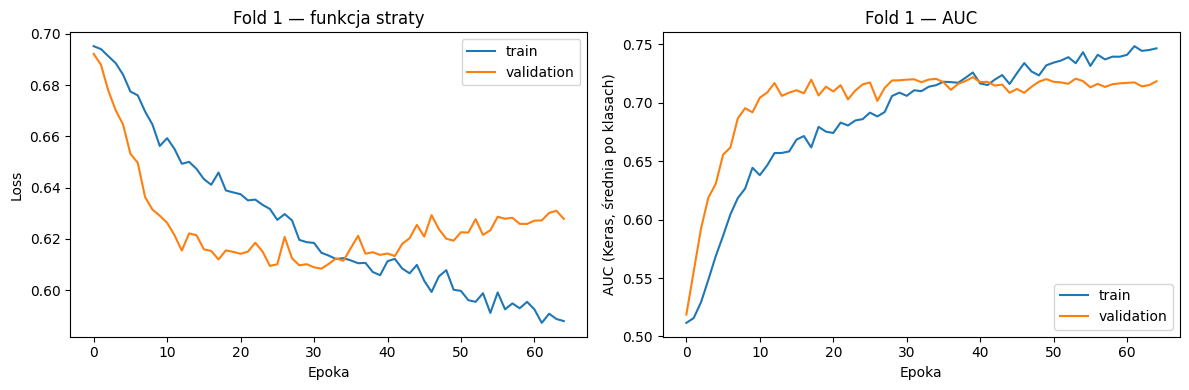

In [ ]:
show_fold = FOLDS_TO_RUN[0]
h = histories[show_fold]
fig, ax = plt.subplots(1, 2, figsize=(12,4))
ax[0].plot(h['loss'], label='train')
ax[0].plot(h['val_loss'], label='validation')
ax[0].set(xlabel='Epoka', ylabel='Loss', title=f'Fold {show_fold} — funkcja straty')
ax[0].legend()
ax[1].plot(h['auc'], label='train')
ax[1].plot(h['val_auc'], label='validation')
ax[1].set(xlabel='Epoka', ylabel='AUC (Keras, średnia po klasach)', title=f'Fold {show_fold} — AUC')
ax[1].legend()
plt.tight_layout()
plt.show()

## 8. Rzeczywista macierz pomyłek, ROC i metryki

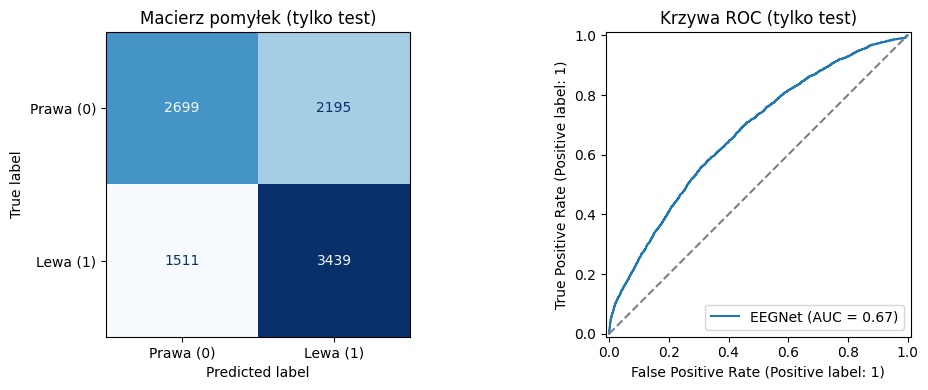

,wartość
roc_auc,0.6717
average_precision,0.6694
accuracy,0.6235
balanced_accuracy,0.6231
f1,0.6498
precision,0.6104
recall,0.6947


In [ ]:
y_true = pred_df['y_true'].to_numpy(dtype=np.uint8)
p_left = pred_df['p_left'].to_numpy(dtype=float)
pred = (p_left >= THRESHOLD).astype(np.uint8)
cm = confusion_matrix(y_true, pred, labels=[0,1])
fig, ax = plt.subplots(1, 2, figsize=(11,4))
ConfusionMatrixDisplay(cm, display_labels=['Prawa (0)', 'Lewa (1)']).plot(ax=ax[0], cmap='Blues', colorbar=False)
ax[0].set_title('Macierz pomyłek (tylko test)')
RocCurveDisplay.from_predictions(y_true, p_left, ax=ax[1], name='EEGNet')
ax[1].plot([0,1],[0,1],'--', color='gray')
ax[1].set_title('Krzywa ROC (tylko test)')
plt.tight_layout()
plt.show()
metrics_pooled = score_predictions(y_true, p_left, threshold=THRESHOLD)
display(pd.DataFrame([metrics_pooled]).T.rename(columns={0:'wartość'}).round(4))

## 9. Zapis raportu i kontrola kompletności

Zbiorczy wynik naukowy wymaga **wszystkich pięciu** foldów, czyli jednej predykcji testowej dla każdej epoki. Jeden fold jest tylko próbą techniczną.

In [ ]:
complete = sorted(FOLDS_TO_RUN) == [1,2,3,4,5] and len(pred_df) == len(X)
if complete:
    assert sorted(pred_df['trial_id']) == sorted(trial_ids.tolist())
else:
    print('UWAGA: uruchomiono tylko wybrane foldy. Metryki zbiorcze nie są wynikiem pełnego benchmarku.')
report = {
    'model':'EEGNet-8,2 (Lawhern et al. 2018)',
    'dataset_dir':str(DATA_DIR), 'demo_mode':bool(TRYB_TESTOWY),
    'complete_out_of_fold':bool(complete),
    'folds_completed':list(map(int,FOLDS_TO_RUN)),
    'seed':SEED, 'batch_size':BATCH_SIZE, 'max_epochs':MAX_EPOCHS,
    'test_decision_threshold':THRESHOLD,
    'fold_metrics':fold_results,
    'pooled_completed_test_folds':metrics_pooled,
}
(RESULTS_DIR / 'results.json').write_text(json.dumps(report, indent=2, ensure_ascii=False), encoding='utf-8')
print('Zapisano predykcje:', RESULTS_DIR / 'out_of_fold_predictions.csv')
print('Zapisano raport:', RESULTS_DIR / 'results.json')

Zapisano predykcje: /home/eliza/mgr-phd/results_ica_64ch/eegnet/out_of_fold_predictions.csv
Zapisano raport: /home/eliza/mgr-phd/results_ica_64ch/eegnet/results.json
Następny krok: 03_Analiza_i_porownanie.ipynb
